# 01 — Signal Processing

This notebook processes binary `.Q00` conductivity fluctuation measurements
and creates spectral features for thin-film Bi, Cr, and Fe samples.

It uses the same processing pipeline as `src/signal_processing.py`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = BASE_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

from signal_processing import (
    DATA_DIR,
    PROCESSED_DIR,
    DATASET_PATH,
    FILE_METADATA,
    MATERIAL_NAMES,
    MATERIAL_COLORS,
    read_q00_file,
    split_into_samples,
    compute_spectrum_features,
    process_q00_file,
    process_file,
    build_combined_dataset,
)

print("Data directory:", DATA_DIR)
print("Processed directory:", PROCESSED_DIR)
print("Combined dataset:", DATASET_PATH)

Data directory: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\q00
Processed directory: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed
Combined dataset: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\conductivity_features.csv


## Input data

In [2]:
q00_files = sorted(DATA_DIR.glob("*.Q00"))

print(f"Found {len(q00_files)} .Q00 files")

for file_path in q00_files:
    print(file_path.name)

Found 37 .Q00 files
AL103C01.Q00
AL103C02.Q00
BI105C01.Q00
BI105C02.Q00
BI106C01.Q00
BI106C02.Q00
BI202C01.Q00
BI202C02.Q00
BI304C01.Q00
BI304C02.Q00
CO105C01.Q00
CO105C02.Q00
COB01C01.Q00
COB01C02.Q00
COB01C03.Q00
CR202C01.Q00
CR202C02.Q00
CR205C01.Q00
CR205C02.Q00
CR206C01.Q00
CR206C02.Q00
CR304C01.Q00
CR304C02.Q00
FE104C01.Q00
FE104C02.Q00
FE105C01.Q00
FE105C02.Q00
FE106C01.Q00
FE106C02.Q00
FE202C01.Q00
FE202C02.Q00
XXX01C01.Q00
XXX01C02.Q00
XXX01C03.Q00
XXX01C04.Q00
XXX01C05.Q00
XXX01C06.Q00


## File metadata

Each file has known material, measurement year, irradiation status,
measurement period, and sampling rate.

In [3]:
metadata_df = pd.DataFrame(FILE_METADATA).T

metadata_df

,material,year,irradiated,measurement_period,sampling_rate_hz
BI202C01,BI,2005,False,2005-08-14_2005-08-29,1.73
BI304C01,BI,2005,False,2005-09-02_2005-10-13,1.73
CR202C01,CR,2005,False,2005-08-14_2005-08-29,1.73
CR304C01,CR,2005,False,2005-09-02_2005-10-13,1.73
FE202C01,FE,2005,False,2005-08-14_2005-08-29,1.73
FE104C01,FE,2005,False,2005-09-02_2005-10-13,1.73
BI105C01,BI,2006,True,2006-03-31_2006-04-29,1.73
BI106C01,BI,2006,True,2006-04-29_2006-06-30,1.73
CR205C01,CR,2006,True,2006-03-31_2006-04-29,1.73
CR206C01,CR,2006,True,2006-04-29_2006-06-30,1.73


## Read one binary file

The reader extracts calibration coefficients, record metadata, and raw ADC codes.

In [4]:
example_file_stem = "BI202C01"
example_file = DATA_DIR / f"{example_file_stem}.Q00"

records = list(read_q00_file(example_file))

print(f"File: {example_file.name}")
print(f"Number of records: {len(records)}")
print(f"Points in first record: {len(records[0]['codes'])}")

records[0]

File: BI202C01.Q00
Number of records: 147
Points in first record: 8192


{'km': 0.06960000097751617,
 'ku': 67.19999694824219,
 'jd1': 2453597.889652778,
 'jd2': 2453597.9444212965,
 'up1': 12.630000114440918,
 'up2': 12.623187065124512,
 'kc': 204800,
 'codes': array([2555, 1543, 1453, ..., 1661, 1534, 1520],
       shape=(8192,), dtype=int16)}

## Split signal into overlapping samples

The default configuration uses 128-point samples with 50% overlap.

In [5]:
sample_length = 128
overlap_mode = 2

samples = split_into_samples(
    codes=records[0]["codes"],
    sample_length=sample_length,
    overlap_mode=overlap_mode,
)

print(f"Number of samples: {len(samples)}")
print(f"Sample shape: {samples[0].shape}")

Number of samples: 127
Sample shape: (128,)


## Process one file

For every sample, the pipeline removes a linear trend, applies a Blackman
window, computes the spectrum, and extracts `gamma` and `energy`.

In [6]:
df_example = process_file(
    input_dir=DATA_DIR,
    file_stem=example_file_stem,
    output_dir=PROCESSED_DIR,
    sampling_rate=FILE_METADATA[example_file_stem]["sampling_rate_hz"],
)

df_example.head()

BI202C01: 32187 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\BI202C01_features.csv


,gamma,energy,jd1,jd2,file,material,material_name,year,measurement_period,irradiated,sampling_rate_hz,log_energy,used_for_training
0,0.398660,1.571536e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.803676,True
1,-0.175839,3.100287e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.508598,True
2,-0.094906,1.338760e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.873297,True
3,-0.136083,1.224634e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.911994,True
4,-0.094538,1.233776e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.908764,True


In [7]:
df_example[["gamma", "energy", "log_energy"]].describe()

,gamma,energy,log_energy
count,32187.000000,3.218700e+04,32187.000000
mean,-0.470109,2.223982e-04,-6.796797
std,0.540253,6.262858e-04,3.002363
min,-3.224360,1.081987e-35,-30.000000
25%,-0.833236,1.472158e-09,-8.832046
50%,-0.361293,1.835155e-08,-7.736327
75%,-0.064361,2.301790e-05,-4.637935
max,1.030530,1.030319e-02,-1.987028


## Build combined dataset

This processes all available `.Q00` files and saves both individual feature
files and the combined dataset.

In [8]:
df = build_combined_dataset()

df.head()

BI202C01: 32187 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\BI202C01_features.csv


BI304C01: 94551 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\BI304C01_features.csv


CR202C01: 32187 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\CR202C01_features.csv


CR304C01: 94551 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\CR304C01_features.csv


FE202C01: 32187 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\FE202C01_features.csv


...

CR206C01: 143237 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\CR206C01_features.csv


FE105C01: 66900 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\FE105C01_features.csv


FE106C01: 143237 samples processed -> C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\FE106C01_features.csv


Combined dataset saved: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\conductivity_features.csv
Total samples: 1145619


,gamma,energy,jd1,jd2,file,material,material_name,year,measurement_period,irradiated,sampling_rate_hz,log_energy,used_for_training
0,0.398660,1.571536e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.803676,True
1,-0.175839,3.100287e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.508598,True
2,-0.094906,1.338760e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.873297,True
3,-0.136083,1.224634e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.911994,True
4,-0.094538,1.233776e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005,2005-08-14_2005-08-29,False,1.73,-8.908764,True


## Dataset overview

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1145619 entries, 0 to 1145618
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   gamma               1145619 non-null  float64
 1   energy              1145619 non-null  float64
 2   jd1                 1145619 non-null  float64
 3   jd2                 1145619 non-null  float64
 4   file                1145619 non-null  str    
 5   material            1145619 non-null  str    
 6   material_name       1145619 non-null  str    
 7   year                1010625 non-null  object 
 8   measurement_period  1145619 non-null  str    
 9   irradiated          1145619 non-null  bool   
 10  sampling_rate_hz    1145619 non-null  float64
 11  log_energy          1145619 non-null  float64
 12  used_for_training   1145619 non-null  bool   
dtypes: bool(2), float64(6), object(1), str(4)
memory usage: 98.3+ MB


In [10]:
df["material"].value_counts()

material
BI     336875
CR     336875
FE     336875
XXX    134994
Name: count, dtype: int64

In [11]:
df.groupby(["material", "irradiated"])[["gamma", "log_energy"]].agg(
    ["count", "mean", "std"]
)

gamma                     log_energy             \
                      count      mean       std      count       mean   
material irradiated                                                     
BI       False       126738 -0.212085  0.399920     126738  -8.149384   
         True        210137 -0.345448  0.347608     210137  -8.696621   
CR       False       126738 -0.324069  0.552037     126738  -8.337995   
         True        210137 -1.213298  0.365795     210137  -9.494306   
FE       False       126738 -0.194396  0.363472     126738  -7.350684   
         True        210137 -0.009327  0.251260     210137  -6.672222   
XXX      False       134994 -0.117057  0.283738     134994 -11.071926   

                               
                          std  
material irradiated            
BI       False       1.716858  
         True        0.236670  
CR       False       0.265002  
         True        5.173035  
FE       False       1.185368  
         True        0.256612  
XXX      False       0.536029

## Spectral feature distribution

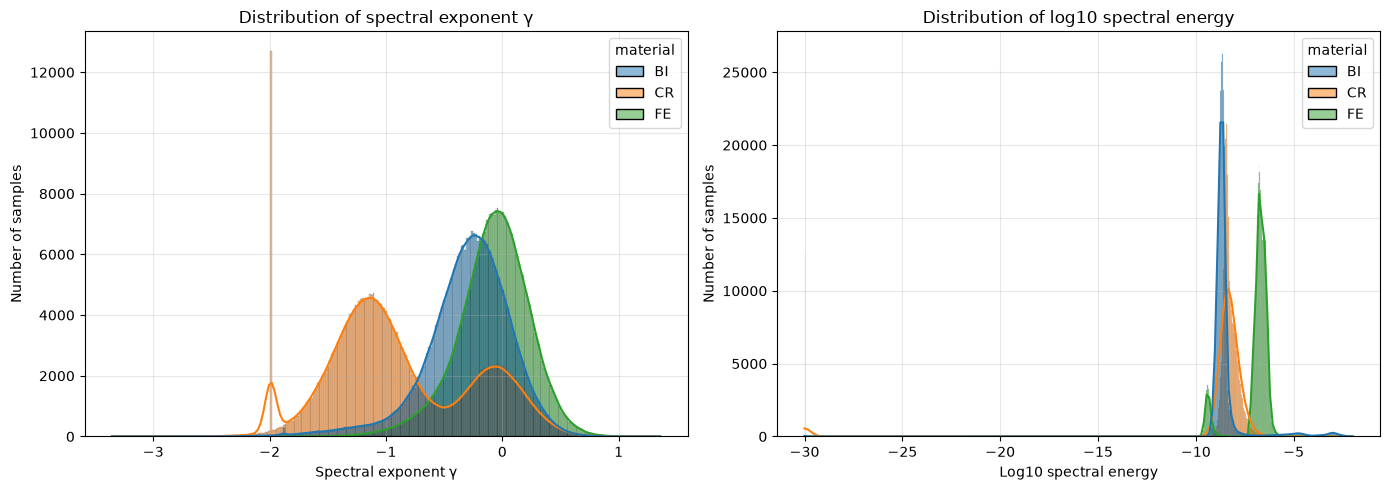

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df[df["material"] != "XXX"],
    x="gamma",
    hue="material",
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Distribution of spectral exponent γ")
axes[0].set_xlabel("Spectral exponent γ")
axes[0].set_ylabel("Number of samples")
axes[0].grid(True, alpha=0.3)

sns.histplot(
    data=df[df["material"] != "XXX"],
    x="log_energy",
    hue="material",
    kde=True,
    ax=axes[1],
)
axes[1].set_title("Distribution of log10 spectral energy")
axes[1].set_xlabel("Log10 spectral energy")
axes[1].set_ylabel("Number of samples")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Stable vs irradiated films

Irradiated films are not used for training. They are compared with stable
films to identify possible radiation-induced changes in noise features.

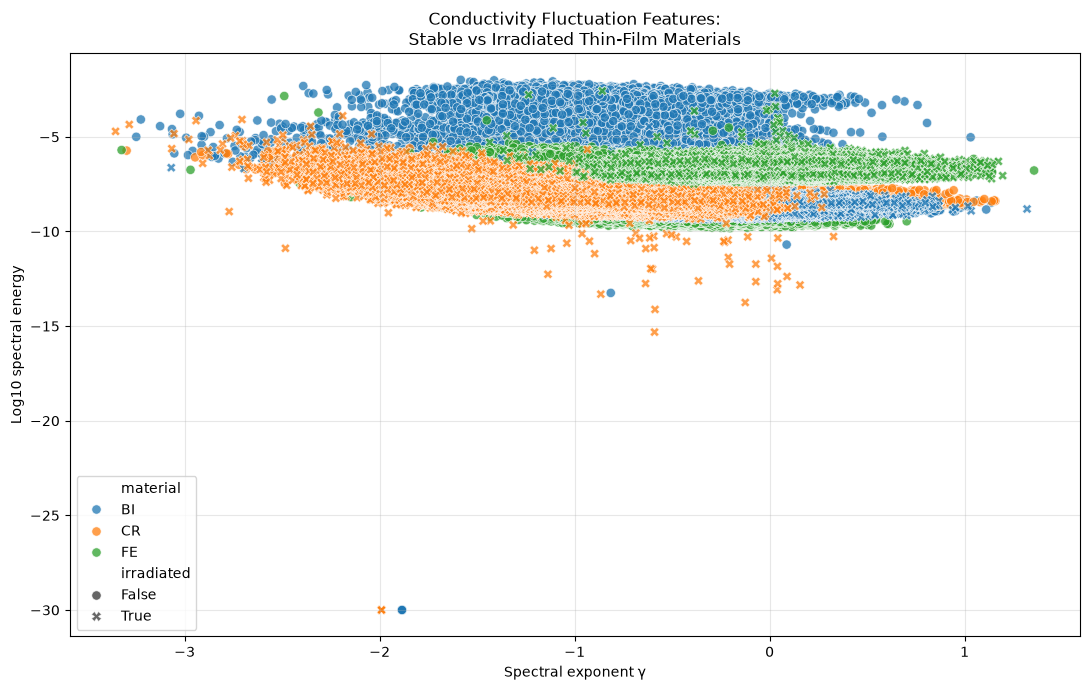

In [13]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df[df["material"] != "XXX"],
    x="gamma",
    y="log_energy",
    hue="material",
    style="irradiated",
    s=45,
    alpha=0.75,
)

plt.xlabel("Spectral exponent γ")
plt.ylabel("Log10 spectral energy")
plt.title(
    "Conductivity Fluctuation Features:\n"
    "Stable vs Irradiated Thin-Film Materials"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Check saved dataset

In [14]:
df_loaded = pd.read_csv(DATASET_PATH)

print(f"Saved dataset: {DATASET_PATH}")
print(f"Rows: {len(df_loaded)}")
print(f"Files: {df_loaded['file'].nunique()}")

df_loaded.head()

Saved dataset: C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\conductivity_features.csv
Rows: 1145619
Files: 15


,gamma,energy,jd1,jd2,file,material,material_name,year,measurement_period,irradiated,sampling_rate_hz,log_energy,used_for_training
0,0.398660,1.571536e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.803676,True
1,-0.175839,3.100287e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.508598,True
2,-0.094906,1.338760e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.873297,True
3,-0.136083,1.224634e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.911994,True
4,-0.094538,1.233776e-09,2.453598e+06,2.453598e+06,BI202C01,BI,Bismuth (Bi),2005.0,2005-08-14_2005-08-29,False,1.73,-8.908764,True


## Output files

In [15]:
processed_files = sorted(PROCESSED_DIR.glob("*_features.csv"))

print(f"Individual feature files: {len(processed_files)}")

for file_path in processed_files:
    print(file_path.name)

print("\nCombined dataset:")
print(DATASET_PATH)

Individual feature files: 16
BI105C01_features.csv
BI106C01_features.csv
BI202C01_features.csv
BI304C01_features.csv
conductivity_features.csv
CR202C01_features.csv
CR205C01_features.csv
CR206C01_features.csv
CR304C01_features.csv
FE104C01_features.csv
FE105C01_features.csv
FE106C01_features.csv
FE202C01_features.csv
XXX01C01_features.csv
XXX01C03_features.csv
XXX01C05_features.csv

Combined dataset:
C:\Users\ka_te\Desktop\github-projects\vkr-conductivity-analysis\data\processed\conductivity_features.csv
